# Seleccion de Puntos Agricolas

In [79]:
import geopandas as gpd
from config.paths import datapaths
from config.links import USOV_API
import os
import pandas as pd

folders = [file.split("/")[-1].replace(".zip", "") for file in USOV_API]


# Edicion 2005

In [80]:

folder_map1 = datapaths['raw']['INEGI'] / folders[0] / "shp"
subfolders = os.listdir(folder_map1)
shp_1 = []
for subf in subfolders:
    if subf[-1] in ["v", "g", "c"]:
        path = folder_map1 / subf
        for file in os.listdir(path):
            if file.endswith(".shp"):
                shp_1.append(path / file)

shp_1

[PosixPath('/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/702825007022_s/shp/us250s3c/us250s3c.shp'),
 PosixPath('/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/702825007022_s/shp/us250s3g/us250s3g.shp'),
 PosixPath('/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/702825007022_s/shp/us250s3v/us250s3v.shp')]

In [81]:
usov_2005 = [gpd.read_file(file) for file in shp_1]

Index(['CODIGO', 'PTOVERIF', 'ASOCIACION', 'TIP_INFO', 'CULTI1', 'CULTI2',
       'CULTI3', 'COORD_X', 'COORD_Y', 'CLAVE_CONJ', 'geometry'],
      dtype='str')


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

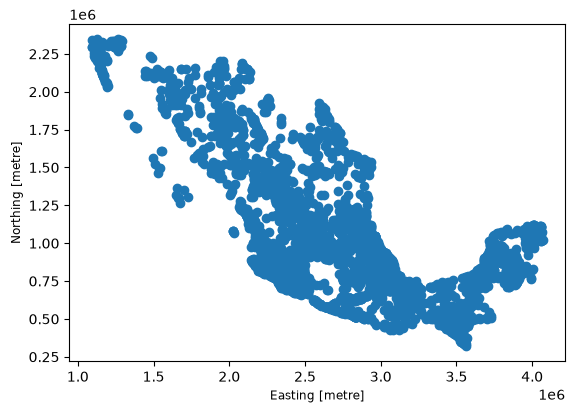

In [82]:
df1 = usov_2005[0]
print(df1.columns)
agro1 = df1[df1['TIP_INFO']== "AGRICOLA-PECUARIA-FORESTAL"]
agro1.plot()

(22451, 14)


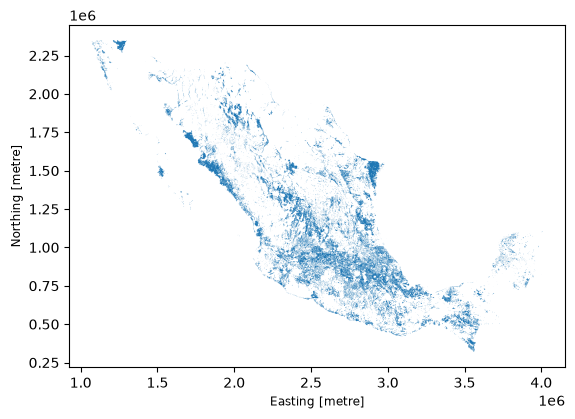

In [83]:
df2 = usov_2005[1]

agro2 = df2[df2['AGECOSIS']== "AGRICOLA"]
agro2.plot()
print(agro2.shape)

Index(['AREA', 'PERIMETER', 'USV250S3V_', 'USV250S3V1', 'CLAVE', 'CODIGO',
       'CLAVEFOT', 'TIP_INFO', 'TIP_ECOV', 'TIP_VEG', 'DESVEG', 'FASE_VS',
       'OTROS', 'geometry'],
      dtype='str')


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

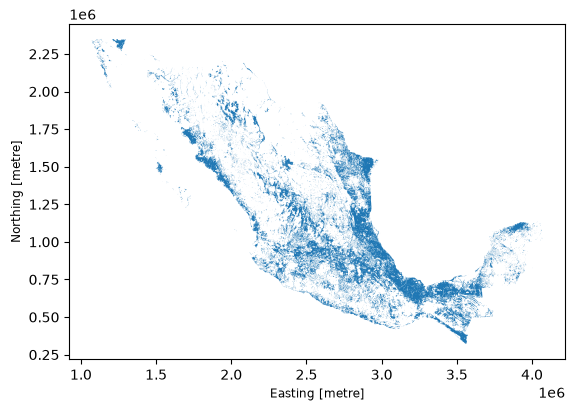

In [84]:
df3 = usov_2005[-1]
print(df3.columns)
agro3 = df3[df3['TIP_INFO']=="AGRICOLA-PECUARIA-FORESTAL"].reset_index(drop=True)
agro3.plot()

In [85]:
shp_1

[PosixPath('/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/702825007022_s/shp/us250s3c/us250s3c.shp'),
 PosixPath('/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/702825007022_s/shp/us250s3g/us250s3g.shp'),
 PosixPath('/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/702825007022_s/shp/us250s3v/us250s3v.shp')]

Notemos que `agro3` no separa entre agricola, pecuaria y forestal. Por lo tanto, decidimos ignorarlo. Luego, `agro1` solo aplica a ciertos cultivos. Entonces, nuestro mapa de referencia será `agro2`

In [86]:
agro_ref = agro2.copy().to_crs(epsg=6372)
agro1 = agro1.to_crs(epsg=6372)

Ahora debemos hacer la verificación de que los puntos de agro1 esten en nuestra referencia.

In [88]:
norm_agropoints = pd.DataFrame(index=agro_ref.geometry, columns=agro1.geometry)

for t, c in enumerate(norm_agropoints.columns):
    print(f"{t / norm_agropoints.shape[1] * 100} %")
    norm_agropoints[c] = agro_ref.geometry.apply(lambda x: x.contains(c)).tolist()


0.0 %
0.027359781121751026 %
0.05471956224350205 %
0.08207934336525308 %
0.1094391244870041 %
0.13679890560875513 %
0.16415868673050615 %
0.19151846785225718 %
0.2188782489740082 %
0.24623803009575923 %
0.27359781121751026 %
0.3009575923392613 %
0.3283173734610123 %
0.35567715458276333 %
0.38303693570451436 %
0.4103967168262654 %
0.4377564979480164 %
0.46511627906976744 %
0.49247606019151846 %
0.5198358413132695 %
0.5471956224350205 %
0.5745554035567715 %
0.6019151846785226 %
0.6292749658002736 %
0.6566347469220246 %
0.6839945280437756 %
0.7113543091655267 %
0.7387140902872777 %
0.7660738714090287 %
0.7934336525307797 %
0.8207934336525308 %
0.8481532147742818 %
0.8755129958960328 %
0.9028727770177838 %
0.9302325581395349 %
0.957592339261286 %
0.9849521203830369 %
1.012311901504788 %
1.039671682626539 %
1.06703146374829 %
1.094391244870041 %
1.121751025991792 %
1.149110807113543 %
1.1764705882352942 %
1.2038303693570451 %
1.231190150478796 %
1.2585499316005473 %
1.2859097127222983 %
1.3

In [97]:
check_agropoints = norm_agropoints[~norm_agropoints]

In [102]:
new_agropoints = check_agropoints.dropna(axis=1, how="all").columns.to_list()
ref_agropoints = agro_ref['geometry'].centroid

In [106]:
distance_agropoints = pd.DataFrame(index=ref_agropoints, columns=new_agropoints)

for t, c in enumerate(distance_agropoints.columns):
    print(f"{t / distance_agropoints.shape[1] * 100} %")
    distance_agropoints[c] = ref_agropoints.apply(lambda x: x.distance(c)).tolist()


0.0 %
0.027359781121751026 %
0.05471956224350205 %
0.08207934336525308 %
0.1094391244870041 %
0.13679890560875513 %
0.16415868673050615 %
0.19151846785225718 %
0.2188782489740082 %
0.24623803009575923 %
0.27359781121751026 %
0.3009575923392613 %
0.3283173734610123 %
0.35567715458276333 %
0.38303693570451436 %
0.4103967168262654 %
0.4377564979480164 %
0.46511627906976744 %
0.49247606019151846 %
0.5198358413132695 %
0.5471956224350205 %
0.5745554035567715 %
0.6019151846785226 %
0.6292749658002736 %
0.6566347469220246 %
0.6839945280437756 %
0.7113543091655267 %
0.7387140902872777 %
0.7660738714090287 %
0.7934336525307797 %
0.8207934336525308 %
0.8481532147742818 %
0.8755129958960328 %
0.9028727770177838 %
0.9302325581395349 %
0.957592339261286 %
0.9849521203830369 %
1.012311901504788 %
1.039671682626539 %
1.06703146374829 %
1.094391244870041 %
1.121751025991792 %
1.149110807113543 %
1.1764705882352942 %
1.2038303693570451 %
1.231190150478796 %
1.2585499316005473 %
1.2859097127222983 %
1.3

In [117]:
new_points = distance_agropoints[distance_agropoints > 9_000].dropna(axis=1, how="any").columns

In [129]:
selected_agro1 = agro1[agro1["geometry"].isin(new_points)]
selected_agro1 = selected_agro1.reset_index(drop=True)
selected_agro1

,CODIGO,PTOVERIF,ASOCIACION,TIP_INFO,CULTI1,CULTI2,CULTI3,COORD_X,COORD_Y,CLAVE_CONJ,geometry
0,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,97.2,0,0,3379820.894,543899.342,E1511,POINT (3379842.101 543806.167)
1,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,98.2,24.,101.,3392344.105,548651.099,E1511,POINT (3392365.054 548558.074)
2,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,101.,0,0,3370873.818,514073.835,E1511,POINT (3370894.699 513979.338)
3,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,98.,28.,0,3500607.911,511039.884,E1511,POINT (3500624.449 510944.423)
4,10000000050,N/A,CODIGOS DE CULTIVOS N0 ASOCIADOS A PUNTOS DE ...,AGRICOLA-PECUARIA-FORESTAL,26.1,26.3,0,3525020.568,578175.135,E1511,POINT (3525037.638 578084.36)
...,...,...,...,...,...,...,...,...,...,...,...
424,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,158.1,10.,148.1,1282125.721,2339896.635,I1112,POINT (1282204.167 2339882.994)
425,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,148.3,166.20,0,1232712.802,2333717.240,I1112,POINT (1232791.506 2333703.633)
426,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,158.1,148.,8.,1280509.687,2310894.877,I1112,POINT (1280585.921 2310881.59)
427,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,158.1,148.,0,1218144.411,2334715.056,I1112,POINT (1218223.343 2334701.236)


In [130]:
agro_ref = pd.concat([agro_ref, selected_agro1]).reset_index(drop=True)
agro_ref

,AREA,PERIMETER,US250S3G_,US250S3G_I,CLAVE,CODIGO,TIP_INFO,AGECOSIS,TIPAGES,TIP_PLAN,...,geometry,index,PTOVERIF,ASOCIACION,CULTI1,CULTI2,CULTI3,COORD_X,COORD_Y,CLAVE_CONJ
0,4.633373e+06,13581.92896,10.0,9.0,TA,10101040104,AGRICOLA-PECUARIA-FORESTAL,AGRICOLA,AGRICULTURA DE TEMPORAL,NINGUNO,...,"POLYGON ((1136070.973 2349311.17, 1135576.708 ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,9.546984e+05,4877.76142,11.0,10.0,TA,10101040104,AGRICOLA-PECUARIA-FORESTAL,AGRICOLA,AGRICULTURA DE TEMPORAL,NINGUNO,...,"POLYGON ((1138519.712 2349299.292, 1138605.842...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.148201e+09,949943.86285,14.0,13.0,RAS,10102040102,AGRICOLA-PECUARIA-FORESTAL,AGRICOLA,AGRICULTURA DE RIEGO,NINGUNO,...,"POLYGON ((1221206.463 2348805.866, 1220913.621...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4.483358e+06,15305.95468,18.0,17.0,RAP,10102040103,AGRICOLA-PECUARIA-FORESTAL,AGRICOLA,AGRICULTURA DE RIEGO,NINGUNO,...,"POLYGON ((1135397.765 2345496.613, 1135408.896...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.123954e+06,4351.31791,21.0,20.0,TA,10101040104,AGRICOLA-PECUARIA-FORESTAL,AGRICOLA,AGRICULTURA DE TEMPORAL,NINGUNO,...,"POLYGON ((1108152.956 2347146.191, 1108002.713...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24162,NaN,NaN,NaN,NaN,NaN,10000000051,AGRICOLA-PECUARIA-FORESTAL,NaN,NaN,NaN,...,POINT (1282204.167 2339882.994),NaN,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,158.1,10.,148.1,1282125.721,2339896.635,I1112
24163,NaN,NaN,NaN,NaN,NaN,10000000051,AGRICOLA-PECUARIA-FORESTAL,NaN,NaN,NaN,...,POINT (1232791.506 2333703.633),NaN,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,148.3,166.20,0,1232712.802,2333717.240,I1112
24164,NaN,NaN,NaN,NaN,NaN,10000000051,AGRICOLA-PECUARIA-FORESTAL,NaN,NaN,NaN,...,POINT (1280585.921 2310881.59),NaN,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,158.1,148.,8.,1280509.687,2310894.877,I1112
24165,NaN,NaN,NaN,NaN,NaN,10000000051,AGRICOLA-PECUARIA-FORESTAL,NaN,NaN,NaN,...,POINT (1218223.343 2334701.236),NaN,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,158.1,148.,0,1218144.411,2334715.056,I1112


# Edicion 2009

In [138]:
folder_map2 = datapaths['raw']['INEGI']/"702825007023_s"/" shape"
subfolders = os.listdir(folder_map1)
shp_2 = []
for subf in subfolders:
    if subf[-1] in ["v", "g", "c"]:
        path = folder_map1 / subf
        for file in os.listdir(path):
            if file.endswith(".shp"):
                shp_2.append(path / file)
usov_2009 = [gpd.read_file(file) for file in shp_1]
shp_2

[PosixPath('/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/702825007022_s/shp/us250s3c/us250s3c.shp'),
 PosixPath('/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/702825007022_s/shp/us250s3g/us250s3g.shp'),
 PosixPath('/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/702825007022_s/shp/us250s3v/us250s3v.shp')]

In [142]:
df21 = usov_2009[0]
agro21 = df21[df21['TIP_INFO'] == "AGRICOLA-PECUARIA-FORESTAL"]
agro21

,CODIGO,PTOVERIF,ASOCIACION,TIP_INFO,CULTI1,CULTI2,CULTI3,COORD_X,COORD_Y,CLAVE_CONJ,geometry
0,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,98.,101.,136.,3457833.253,555646.198,E1511,POINT (3457852.255 555553.489)
1,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,98.,0,0,3422214.959,557124.331,E1511,POINT (3422235.18 557031.632)
2,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,97.2,0,0,3379820.894,543899.342,E1511,POINT (3379842.101 543806.167)
3,10000000050,10,CODIGOS DE CULTIVOS ASOCIADOS A PUNTOS DE VERI...,AGRICOLA-PECUARIA-FORESTAL,98.,24.,0,3465158.827,516004.542,E1511,POINT (3465176.631 515909.346)
4,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,98.,0,0,3477410.341,556571.092,E1511,POINT (3477428.685 556478.551)
...,...,...,...,...,...,...,...,...,...,...,...
3690,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,172,85.,54.2,1129378.641,2199858.471,H1102,POINT (1129462.253 2199841.956)
3691,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,85.,45.16,0,1154241.149,2180204.512,H1102,POINT (1154326.198 2180186.668)
3692,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,43.,45.16,128.1,1115544.878,2257108.808,H1102,POINT (1115623.192 2257092.222)
3693,10000000051,N/A,CODIGOS DE CULTIVOS NO ASOCIADOS A PUNTOS DE V...,AGRICOLA-PECUARIA-FORESTAL,62.,0,0,1111417.773,2253991.802,H1102,POINT (1111495.739 2253975.409)


In [148]:
df22 = usov_2009[1]
agro_ref2 = df22[df22['AGECOSIS']=="AGRICOLA"]
agro_ref2.shape

(22451, 14)

In [157]:
agro_ref['Centro'] = agro_ref['geometry'].centroid
agro_ref.head()

,AREA,PERIMETER,US250S3G_,US250S3G_I,CLAVE,CODIGO,TIP_INFO,AGECOSIS,TIPAGES,TIP_PLAN,...,index,PTOVERIF,ASOCIACION,CULTI1,CULTI2,CULTI3,COORD_X,COORD_Y,CLAVE_CONJ,Centro
0,4.633373e+06,13581.92896,10.0,9.0,TA,10101040104,AGRICOLA-PECUARIA-FORESTAL,AGRICOLA,AGRICULTURA DE TEMPORAL,NINGUNO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (1135724.956 2347096.596)
1,9.546984e+05,4877.76142,11.0,10.0,TA,10101040104,AGRICOLA-PECUARIA-FORESTAL,AGRICOLA,AGRICULTURA DE TEMPORAL,NINGUNO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (1138560.439 2348345.516)
2,2.148201e+09,949943.86285,14.0,13.0,RAS,10102040102,AGRICOLA-PECUARIA-FORESTAL,AGRICOLA,AGRICULTURA DE RIEGO,NINGUNO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (1256224.034 2325192.857)
3,4.483358e+06,15305.95468,18.0,17.0,RAP,10102040103,AGRICOLA-PECUARIA-FORESTAL,AGRICOLA,AGRICULTURA DE RIEGO,NINGUNO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (1133252.195 2346614.737)
4,1.123954e+06,4351.31791,21.0,20.0,TA,10101040104,AGRICOLA-PECUARIA-FORESTAL,AGRICOLA,AGRICULTURA DE TEMPORAL,NINGUNO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,POINT (1108040.623 2347662.982)


In [ ]:
agro21 = agro21.to_crs(epsg=6372)

norm_distances2 = pd.DataFrame(index=agro_ref['Centro'], columns = agro21.geometry)

for t, c in enumerate(norm_distances2.columns):
    print(t / len(norm_distances2.columns) * 100)
    norm_distances2[c] = agro_ref['Centro'].apply(lambda x: x.distance(c)).tolist()


0.0
0.004454144581533116
0.008908289163066232
0.013362433744599351
0.017816578326132464
0.022270722907665585
0.026724867489198702
0.031179012070731815
0.03563315665226493
0.04008730123379805
0.04454144581533117
0.04899559039686428
0.053449734978397404
0.05790387955993051
0.06235802414146363
0.06681216872299675
0.07126631330452986
0.07572045788606298
0.0801746024675961
0.08462874704912922
0.08908289163066234
0.09353703621219546
0.09799118079372857
0.10244532537526169
0.10689946995679481
0.11135361453832793
0.11580775911986102
0.12026190370139414
0.12471604828292726
0.12917019286446038
0.1336243374459935
0.1380784820275266
0.14253262660905971
0.14698677119059284
0.15144091577212596
0.15589506035365908
0.1603492049351922
0.16480334951672532
0.16925749409825844
0.17371163867979156
0.17816578326132468
0.1826199278428578
0.18707407242439092
0.191528217005924
0.19598236158745713
0.20043650616899025
0.20489065075052337
0.2093447953320565
0.21379893991358961
0.21825308449512273
0.22270722907665

In [182]:
new_points = norm_distances2[norm_distances2 > 9_000].dropna(axis=1, how="any").columns

En este caso ya no agregamos más puntos. Ahora seguimos con el resto de puntos.

In [ ]:
agro_ref2 = agro_ref2.to_crs(epsg=6372)
agro_ref2['Centro'] = agro_ref2.geometry.centroid
norm_distances3 = pd.DataFrame(index=agro_ref['Centro'], columns = agro_ref2['Centro'])

for t, c in enumerate(norm_distances3.columns):
    print(t / len(norm_distances3.columns) * 100)
    norm_distances3[c] = agro_ref['Centro'].apply(lambda x: x.distance(c)).tolist()

In [196]:
delete_similars= norm_distances3.drop(columns = [c for c in norm_distances3.columns if c in norm_distances3.index])

In [197]:
delete_similars

Centro
Centro
POINT (1135724.956 2347096.596)
POINT (1138560.439 2348345.516)
POINT (1256224.034 2325192.857)
POINT (1133252.195 2346614.737)
POINT (1108040.623 2347662.982)
...
POINT (1282204.167 2339882.994)
POINT (1232791.506 2333703.633)
POINT (1280585.921 2310881.59)


Concluyendo que los datos de la siguiente tabla se preservaron en los datos anteriores.

In [198]:
folder3 = "/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/702825007024_s/conjunto_de_datos/CAPAS"
os.listdir(folder3)

['usv250s5a',
 'usv250s5c',
 'usv250s5d',
 'usv250s5e',
 'usv250s5f',
 'usv250s5g',
 'usv250s5h',
 'usv250s5i',
 'usv250s5l',
 'usv250s5n',
 'usv250s5o',
 'usv250s5p',
 'usv250s5v']

In [42]:
file4 = "/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/889463173359_s/conjunto_de_datos/usv250s6_union.shp"

df4 = gpd.read_file(file4)
df4.shape

(142760, 5)

In [36]:
agro4 = df4[df4['DESCRIPCIO'].isin([col for col in df4['DESCRIPCIO'].unique() if col.startswith("AGRI")])]

(26907, 5)


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

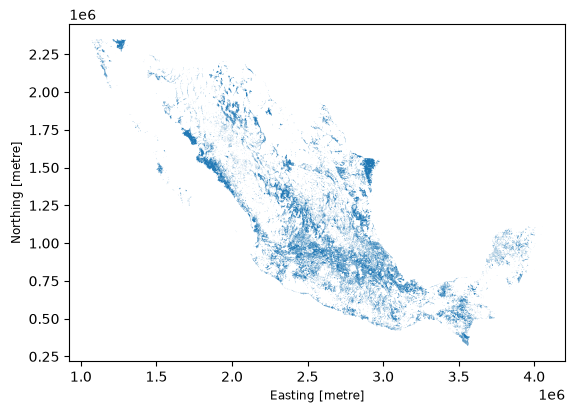

In [45]:
print(agro4.shape)
agro4.plot()

In [ ]:
file5 = "/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/889463598459_s/conjunto_de_datos"


In [39]:
file6 = "/home/dusty/Documents/Repositories/proyecto_agronomia/data/raw/INEGI/889463842781_s/conjunto_de_datos/cdv_usuev250sVII_cnal.shp"
df6 = gpd.read_file(file6)
df6.shape

(179099, 3)

In [43]:
agro6 = df6[df6['DESCRIPCIO'].isin([col for col in df6['DESCRIPCIO'].unique() if col.startswith("AGRI")])]


In [44]:
agro6.shape

(35667, 3)

In [47]:
print(agro1.shape)
print(agro2.shape)
print(agro4.shape)
print(agro6.shape)

(17716, 14)
(22451, 14)
(26907, 5)
(35667, 3)


In [ ]:
agro1points = agro1['geometry'].centroid.


18        POINT (1134508.913 2346859.636)
20        POINT (1138560.453 2348345.502)
40         POINT (1256310.729 2325140.82)
49        POINT (1108040.629 2347662.973)
51         POINT (1106446.109 2347829.96)
                       ...               
105943      POINT (3485574.507 388916.74)
105960     POINT (3489800.926 382761.625)
105964     POINT (3503143.164 370044.428)
105974     POINT (3498858.307 374823.264)
106041     POINT (3538357.784 337352.151)
Length: 17716, dtype: geometry

In [52]:
agro2['Validacion'] = 0

In [54]:
actual_points = len(agro1points)

for t, p in enumerate(agro1points):
    print(f"{t}/{actual_points} {t / actual_points * 100}%", flush=True)
    for reg in agro2.index:
        if agro2.loc[reg, 'geometry'].contains(p):
            agro2.loc[reg, 'Validacion']+=1

0/17716 0.0%
1/17716 0.0056446150372544595%
2/17716 0.011289230074508919%
3/17716 0.01693384511176338%
4/17716 0.022578460149017838%
5/17716 0.028223075186272296%
6/17716 0.03386769022352676%
7/17716 0.039512305260781214%
8/17716 0.045156920298035676%
9/17716 0.05080153533529013%
10/17716 0.05644615037254459%
11/17716 0.06209076540979905%
12/17716 0.06773538044705352%
13/17716 0.07337999548430797%
14/17716 0.07902461052156243%
15/17716 0.0846692255588169%
16/17716 0.09031384059607135%
17/17716 0.0959584556333258%
18/17716 0.10160307067058026%
19/17716 0.10724768570783473%
20/17716 0.11289230074508919%
21/17716 0.11853691578234365%
22/17716 0.1241815308195981%
23/17716 0.12982614585685257%
24/17716 0.13547076089410703%
25/17716 0.14111537593136148%
26/17716 0.14675999096861594%
27/17716 0.15240460600587039%
28/17716 0.15804922104312485%
29/17716 0.16369383608037932%
30/17716 0.1693384511176338%
31/17716 0.17498306615488823%
32/17716 0.1806276811921427%
33/17716 0.18627229622939714%
34/1

In [ ]:
new_pointsagro2[agro2['Validacion'] > 0].shape[0] / actual_points


0.7003273876721607

In [59]:
agro2['Validacion'].value_counts()

Validacion
1    12353
0    10044
2       54
Name: count, dtype: int64

In [64]:
new_points = agro2[agro2['Validacion'] == 0]['geometry'].centroid

In [65]:
new_points


8        POINT (1135724.956 2347096.596)
16       POINT (1133252.195 2346614.737)
25       POINT (1124184.131 2347535.868)
35           POINT (1125693 2346912.286)
50        POINT (1119016.745 2342866.77)
                      ...               
50805     POINT (3555255.484 330088.829)
50806     POINT (3556889.524 331179.146)
50809     POINT (3560044.782 329824.458)
50810     POINT (3557942.217 329418.491)
50811     POINT (3558379.679 325597.162)
Length: 10044, dtype: geometry

In [72]:
distances = pd.DataFrame(index=agro1points, columns = new_points)


In [76]:
for p2 in distances.columns:
    print(p2)
    distances[p2] = agro1points.apply(lambda x: x.distance(p2)).tolist()

POINT (1135724.9556634566 2347096.59564312)
POINT (1133252.1947501667 2346614.7365212305)
POINT (1124184.1306852957 2347535.867579493)
POINT (1125692.9995074258 2346912.28552209)
POINT (1119016.7451435674 2342866.77019753)
POINT (1108652.886031123 2342424.3537704265)
POINT (1268859.307007203 2343809.518704028)
POINT (1109169.6568000887 2341926.135998928)
POINT (1124655.3828408008 2339962.081175724)
POINT (1105903.510546648 2338318.718032501)
POINT (1095861.9808318482 2336491.432230756)
POINT (1082051.116808362 2330980.6415369934)
POINT (1113601.81195036 2330616.2522122744)
POINT (1116366.2211014677 2328108.315114664)
POINT (1110305.9542182253 2328849.1438082564)
POINT (1078318.673218785 2326544.227253402)
POINT (1113360.7872258946 2325614.3206405523)
POINT (1116292.3869870408 2325354.011046082)
POINT (1117092.5285504076 2323292.6553318226)
POINT (1119072.183915986 2323842.5396603416)
POINT (1092887.842901174 2319819.8853675597)
POINT (1088391.9113789436 2314629.9186528022)
POINT (12641

In [84]:
distances[distances > 9000].isna().sum(axis=0).sort_values(ascending=False)

POINT (2740905.704 1548313.207)    29
POINT (2739089.53 1548665.647)     29
POINT (1984580.111 1649339.739)    26
POINT (2014230.059 1565015.468)    26
POINT (2014930.393 1737203.328)    23
                                   ..
POINT (3560191.179 346504.44)       0
POINT (3548523.428 345414.89)       0
POINT (3553556.214 345959.773)      0
POINT (3536305.532 347302.43)       0
POINT (3558293.479 347501.879)      0
Length: 10044, dtype: int64

In [ ]:
agropoints_selected = agro2.copy()
agropoints_selected['Validacion'] = 0
agropoints_selected['Centro'] = agropoints_selected.geometry.centroid

In [110]:
check_forms = pd.DataFrame(index=agro4.geometry, columns=agropoints_selected['Centro'])
check_forms

Centro,POINT (1135724.956 2347096.596),POINT (1138560.439 2348345.516),POINT (1256224.034 2325192.857),POINT (1133252.195 2346614.737),POINT (1108040.623 2347662.982),POINT (1106446.099 2347829.966),POINT (1128031.587 2346523.635),POINT (1124184.131 2347535.868),POINT (1269251.156 2347001.855),POINT (1125693 2346912.286),...,POINT (3721430.573 950189.217),POINT (3733338.548 965174.556),POINT (3733523.063 957776.988),POINT (3735273.477 966019.316),POINT (3735831.935 969597.18),POINT (3733963.638 1031572.708),POINT (3732413.289 1031264.856),POINT (3732620.03 1025781.14),POINT (3723565.694 1034590.483),POINT (3731673.156 1050061.674)
geometry,,,,,,,,,,,,,,,,,,,,,
"POLYGON ((3088879.832 430059.602, 3088848.176 ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((3194357.25 562760.438, 3194474.078 5...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((3254875.377 607407.869, 3254490.47 6...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((3247739.272 612643.89, 3247598.877 6...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((3218295.726 616519.168, 3218252.731 ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"POLYGON ((2192174.409 1065754.168, 2192200.423...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((2171399.221 1066541.58, 2171503.776 ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((2817234.44 1070464.913, 2817155.448 ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [113]:
k = 0
for c in check_forms.columns:
    print(k, k / check_forms.shape[1])
    check_forms[c] = agro4['geometry'].apply(lambda x: x.contains(c)).to_list()
    k+= 1

0 0.0
1 4.4541445815331164e-05
2 8.908289163066233e-05
3 0.0001336243374459935
4 0.00017816578326132465
5 0.00022270722907665583
6 0.000267248674891987
7 0.00031179012070731816
8 0.0003563315665226493
9 0.0004008730123379805
10 0.00044541445815331166
11 0.0004899559039686428
12 0.000534497349783974
13 0.0005790387955993051
14 0.0006235802414146363
15 0.0006681216872299675
16 0.0007126631330452986
17 0.0007572045788606298
18 0.000801746024675961
19 0.0008462874704912921
20 0.0008908289163066233
21 0.0009353703621219545
22 0.0009799118079372856
23 0.0010244532537526168
24 0.001068994699567948
25 0.0011135361453832792
26 0.0011580775911986102
27 0.0012026190370139414
28 0.0012471604828292726
29 0.0012917019286446038
30 0.001336243374459935
31 0.001380784820275266
32 0.0014253262660905972
33 0.0014698677119059284
34 0.0015144091577212596
35 0.0015589506035365908
36 0.001603492049351922
37 0.001648033495167253
38 0.0016925749409825842
39 0.0017371163867979154
40 0.0017816578326132467
41 0.0

In [120]:
s=check_forms[check_forms==True].dropna(axis=0, how="all")

In [121]:
s.dropna(axis=1, how="all")


Centro,POINT (1135724.956 2347096.596),POINT (1256224.034 2325192.857),POINT (1133252.195 2346614.737),POINT (1108040.623 2347662.982),POINT (1106446.099 2347829.966),POINT (1128031.587 2346523.635),POINT (1124184.131 2347535.868),POINT (1269251.156 2347001.855),POINT (1125693 2346912.286),POINT (1105627.083 2345116.07),...,POINT (3557942.217 329418.491),POINT (3558379.679 325597.162),POINT (3721430.573 950189.217),POINT (3733338.548 965174.556),POINT (3733523.063 957776.988),POINT (3735273.477 966019.316),POINT (3735831.935 969597.18),POINT (3732413.289 1031264.856),POINT (3723565.694 1034590.483),POINT (3731673.156 1050061.674)
geometry,,,,,,,,,,,,,,,,,,,,,
"POLYGON ((3088879.832 430059.602, 3088848.176 ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((3194357.25 562760.438, 3194474.078 5...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((3247739.272 612643.89, 3247598.877 6...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((3218295.726 616519.168, 3218252.731 ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((3195804.287 622392.025, 3196022.727 ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"POLYGON ((2164743.213 1061127.543, 2164739.697...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((2171399.221 1066541.58, 2171503.776 ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"POLYGON ((2817234.44 1070464.913, 2817155.448 ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [123]:
s.shape

(15349, 22451)

In [124]:
check_forms.shape

(26907, 22451)